# Spotify Popularity & Audio-Based Recommendation (Fixed)

**Run cells from top to bottom.** Cassandra must be running at `127.0.0.1:9042`.

This version:
- Reads the existing `spotify.song_catalog` table.
- Imports real audio features from the original CSV (required; does not fabricate them).
- Matches rows by normalized `track + artist`, with a track-only fallback.
- Trains the regression model using **audio features only**.
- Uses a custom engagement-derived `popularity_score` as the target.
- Uses small Matplotlib charts (no Plotly/nbformat dependency).
- Avoids overwriting existing Cassandra result rows and existing processed CSV files.

**Important:** The target is a project-defined score based on engagement metrics, not Spotify's official popularity score. If the audio CSV does not match the Cassandra tracks, training stops with a clear diagnostic instead of an empty-data error.


## 1. Imports and configuration

In [4]:
import os
import re
import pickle
import warnings
from uuid import uuid5, NAMESPACE_URL

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cassandra.cluster import Cluster
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from IPython.display import display

OUTPUT_DIR = "spotify_model_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
pd.set_option("display.max_columns", 100)

KEYSPACE = "spotify"
TABLE = "song_catalog"

# Change this to the actual path of your original CSV containing Danceability,
# Energy, Valence, Tempo, etc.
AUDIO_CSV_PATH = "Spotify_Youtube.csv"

AUDIO_CANDIDATES = [
    "danceability", "energy", "key", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence",
    "tempo", "duration_ms", "mode", "time_signature"
]


## 2. Connect to Cassandra and load song catalog

In [5]:
cluster = Cluster(["127.0.0.1"], port=9042)
session = cluster.connect(KEYSPACE)

schema = list(session.execute(
    "SELECT column_name, type FROM system_schema.columns "
    "WHERE keyspace_name=%s AND table_name=%s",
    (KEYSPACE, TABLE)
))
if not schema:
    raise RuntimeError(f"Table {KEYSPACE}.{TABLE} was not found.")

rows = list(session.execute(f"SELECT * FROM {TABLE}"))
df = pd.DataFrame([r._asdict() for r in rows])
if df.empty:
    raise RuntimeError(f"{KEYSPACE}.{TABLE} returned no rows.")

def norm_col(name):
    return re.sub(r"[^a-z0-9]+", "_", str(name).strip().lower()).strip("_")

df.columns = [norm_col(c) for c in df.columns]
print("Cassandra rows:", len(df))
print("Cassandra columns:", df.columns.tolist())
display(df.head())


Cassandra rows: 20626
Cassandra columns: ['song_id', 'album', 'artist', 'comments', 'likes', 'stream', 'track', 'views']


,song_id,album,artist,comments,likes,stream,track,views
0,64585bc9a63a833a4ae4f16d82e1c08b0f0b02081b3843...,Lust For Life,Iggy Pop,2874,280028,323795115.0,The Passenger,31172789
1,10f5531432b363d48718fc93fc78e89bc216419f3e2ebc...,Carrying Your Love With Me,George Strait,10041,268673,111639862.0,Carrying Your Love With Me,52540392
2,d6e297ca0fb0581e0db01650f58415b366dc2cd98ea86c...,Feel Something,Jaymes Young,4405,565570,782970821.0,Infinity,47368786
3,4d6eda2a1825a3c630e4b396bf3f6d0420628a9cc6663f...,Wildcard,Miranda Lambert,5545,140683,136497255.0,Bluebird,23238672
4,76b40e8fd0eb167885c1364276a7524609a3028354fd71...,We Could Be Dancing,Bob Sinclar,1534,44984,18778096.0,We Could Be Dancing,8127251


## 3. Load the original audio-features CSV and match songs

In [6]:
if not os.path.exists(AUDIO_CSV_PATH):
    raise FileNotFoundError(
        f"Audio CSV not found: {os.path.abspath(AUDIO_CSV_PATH)}\n"
        "Put your original CSV in this notebook's folder and set AUDIO_CSV_PATH "
        "to its exact filename. It must contain columns such as Artist, Track, "
        "Danceability, Energy, Valence, Tempo, etc."
    )

audio_df = pd.read_csv(AUDIO_CSV_PATH)
audio_df.columns = [norm_col(c) for c in audio_df.columns]

# Handle common source names after normalization.
source_track = next((c for c in ["track", "title", "track_name", "song"] if c in audio_df.columns), None)
source_artist = next((c for c in ["artist", "artist_name"] if c in audio_df.columns), None)
target_track = next((c for c in ["track", "title", "track_name", "song"] if c in df.columns), None)
target_artist = next((c for c in ["artist", "artist_name"] if c in df.columns), None)

if source_track is None or target_track is None:
    raise ValueError(
        f"Could not identify track columns. CSV columns: {audio_df.columns.tolist()} | "
        f"Cassandra columns: {df.columns.tolist()}"
    )

audio_features = [
    c for c in AUDIO_CANDIDATES
    if c in audio_df.columns and pd.api.types.is_numeric_dtype(
        pd.to_numeric(audio_df[c], errors="coerce")
    )
]
# Convert numeric-looking audio columns explicitly.
for c in audio_features:
    audio_df[c] = pd.to_numeric(audio_df[c], errors="coerce")

if len(audio_features) < 2:
    raise ValueError(
        "Fewer than two actual numeric audio feature columns were found in the CSV. "
        f"Found: {audio_features}. Check the CSV headers and file."
    )

def clean_match_text(series):
    return (
        series.fillna("").astype(str).str.strip().str.lower()
        .str.replace(r"[^a-z0-9]+", " ", regex=True)
        .str.replace(r"\s+", " ", regex=True).str.strip()
    )

audio_df["_track_key"] = clean_match_text(audio_df[source_track])
df["_track_key"] = clean_match_text(df[target_track])

if source_artist and target_artist:
    audio_df["_match_key"] = audio_df["_track_key"] + "|" + clean_match_text(audio_df[source_artist])
    df["_match_key"] = df["_track_key"] + "|" + clean_match_text(df[target_artist])
    lookup = audio_df[["_match_key"] + audio_features].drop_duplicates("_match_key")
    merged = df.merge(lookup, on="_match_key", how="left", suffixes=("", "_audio"))
    # Use track-only fallback for rows that did not match on both artist and track.
    unmatched = merged[audio_features].isna().all(axis=1)
    if unmatched.any():
        track_lookup = audio_df[["_track_key"] + audio_features].drop_duplicates("_track_key")
        fallback = merged.loc[unmatched, ["_track_key"]].merge(track_lookup, on="_track_key", how="left")
        for c in audio_features:
            merged.loc[unmatched, c] = fallback[c].to_numpy()
    df = merged
else:
    lookup = audio_df[["_track_key"] + audio_features].drop_duplicates("_track_key")
    df = df.merge(lookup, on="_track_key", how="left", suffixes=("", "_audio"))

matched_mask = df[audio_features].notna().any(axis=1)
print("Audio CSV rows:", len(audio_df))
print("Audio feature columns:", audio_features)
print(f"Matched Cassandra songs: {int(matched_mask.sum())} / {len(df)} ({matched_mask.mean():.1%})")
display(df.loc[matched_mask, [target_track] + ([target_artist] if target_artist else []) + audio_features].head())

if matched_mask.sum() == 0:
    print("\nSample CSV track/artist:")
    display(audio_df[[source_track] + ([source_artist] if source_artist else [])].head(10))
    print("Sample Cassandra track/artist:")
    display(df[[target_track] + ([target_artist] if target_artist else [])].head(10))
    raise ValueError(
        "No songs matched. Check that this is the correct original CSV and that "
        "the Cassandra track/artist names correspond to it. Training was stopped safely."
    )


Audio CSV rows: 20718
Audio feature columns: ['danceability', 'energy', 'key', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']
Matched Cassandra songs: 20624 / 20626 (100.0%)


,track,artist,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,The Passenger,Iggy Pop,0.498,0.889,0.0,-5.413,0.0546,0.09470,0.000002,0.7330,0.696,134.880,283360.0
1,Carrying Your Love With Me,George Strait,0.629,0.479,10.0,-10.608,0.0271,0.22000,0.000000,0.0587,0.345,138.231,232427.0
2,Infinity,Jaymes Young,0.671,0.673,11.0,-6.941,0.0444,0.14800,0.000053,0.3040,0.494,121.963,237720.0
3,Bluebird,Miranda Lambert,0.661,0.633,7.0,-5.986,0.0348,0.03800,0.000003,0.1240,0.613,81.984,209760.0
4,We Could Be Dancing,Bob Sinclar,0.668,0.808,1.0,-5.292,0.0989,0.00809,0.000214,0.5990,0.789,119.978,164500.0


## 4. Clean columns and create the custom popularity target

In [7]:
# Convert relevant engagement columns to numeric.
def find_col(candidates):
    for candidate in candidates:
        for col in df.columns:
            if col == candidate or candidate in col:
                return col
    return None

track_col = target_track
artist_col = target_artist
id_col = find_col(["song_id", "track_id", "id"])
stream_col = find_col(["stream", "streams"])
views_col = find_col(["views", "view"])
likes_col = find_col(["likes", "like"])
comments_col = find_col(["comments", "comment"])

engagement_cols = [
    c for c in [stream_col, views_col, likes_col, comments_col]
    if c and c in df.columns
]

score_cols = []
for c in engagement_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    logged = np.log1p(df[c].clip(lower=0))
    if logged.notna().any() and logged.max() > logged.min():
        norm_name = c + "_normalized"
        df[norm_name] = (logged - logged.min()) / (logged.max() - logged.min())
        score_cols.append(norm_name)

if not score_cols:
    raise ValueError("No usable stream/view/like/comment columns found to create popularity_score.")

engagement_score = df[score_cols].mean(axis=1) * 100
# This dataset's available target is engagement-based. Audio features are predictors,
# not ingredients in the target, so the model can be trained on audio only.
df["popularity_score"] = engagement_score

print("Engagement fields used to define target:", engagement_cols)
print("Target formula: mean of available log-normalized engagement metrics × 100")
display(df[["popularity_score"] + score_cols].head())


Engagement fields used to define target: ['stream', 'views', 'likes', 'comments']
Target formula: mean of available log-normalized engagement metrics × 100


,popularity_score,stream_normalized,views_normalized,likes_normalized,comments_normalized
0,70.906112,0.893021,0.756382,0.706900,0.479942
1,72.091086,0.844494,0.779266,0.704567,0.555317
2,74.004289,0.933261,0.774724,0.746517,0.505670
3,69.620053,0.853655,0.743507,0.668103,0.519537
4,62.666912,0.763257,0.697453,0.603842,0.442124


## 5. Quick EDA

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
song_id,20626,20626,64585bc9a63a833a4ae4f16d82e1c08b0f0b02081b3843...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
album,20626,11893,Greatest Hits,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
artist,20626,2079,Iggy Pop,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
comments,20626.0,NaN,NaN,NaN,26757.595414,190994.48726,0.0,406.0,2992.5,13701.0,16083138.0
likes,20626.0,NaN,NaN,NaN,644850.872249,1768356.9111,0.0,17489.0,114481.5,498584.0,50788652.0
stream,20626.0,NaN,NaN,NaN,132526838.436003,242163532.641995,0.0,15640639.25,47313987.5,134152065.25,3386520288.0
track,20626,17831,El Ultimo Adiós - Varios Artistas Version,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
views,20626.0,NaN,NaN,NaN,91658690.883012,272024011.631941,0.0,1475674.0,13312239.5,67211024.5,8079649362.0
_track_key,20626,17527,,104,NaN,NaN,NaN,NaN,NaN,NaN,NaN
_match_key,20626,20535,|yoasobi,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_audio_values
danceability,2
energy,2
key,2
loudness,2
speechiness,2
acousticness,2
instrumentalness,2
liveness,2
valence,2
tempo,2


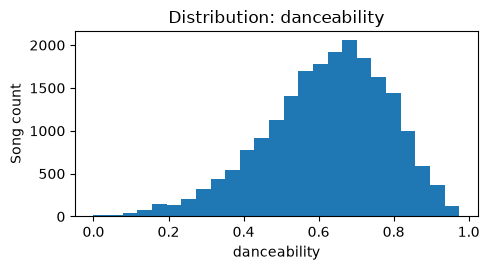

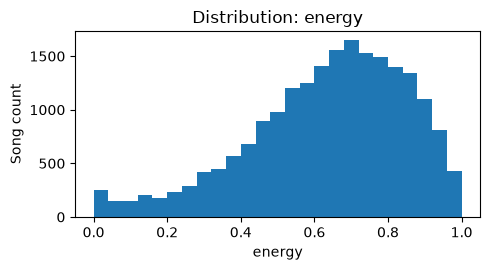

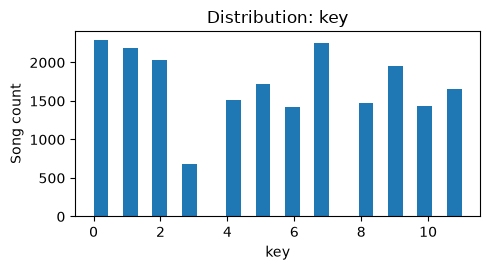

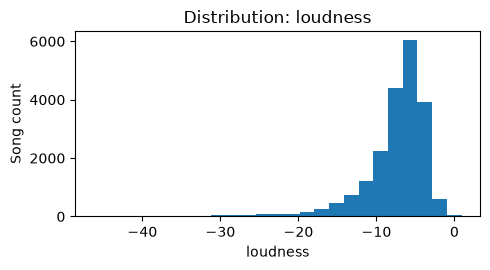

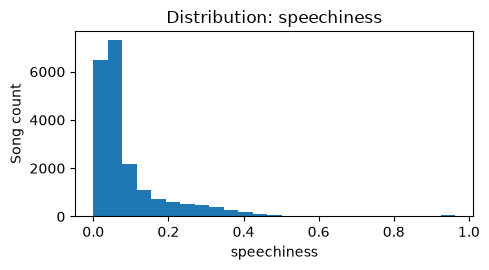

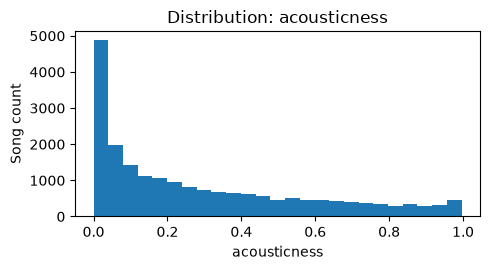

In [8]:
display(df.describe(include="all").T.head(30))

missing_audio = df[audio_features].isna().sum().sort_values(ascending=False)
display(missing_audio.to_frame("missing_audio_values"))

# Small, readable audio feature distributions
for col in audio_features[:6]:
    values = pd.to_numeric(df[col], errors="coerce").dropna()
    if len(values):
        fig, ax = plt.subplots(figsize=(5, 2.8))
        ax.hist(values, bins=25)
        ax.set_title(f"Distribution: {col}")
        ax.set_xlabel(col)
        ax.set_ylabel("Song count")
        plt.tight_layout()
        plt.show()
        plt.close()


## 6. Train model using audio features only

In [13]:

# Audio features + likes + comments only
engagement_features = ["likes", "comments"]

feature_cols = audio_features + [
    c for c in engagement_features
    if c in df.columns and c not in audio_features
]

model_df = df.dropna(subset=["popularity_score"]).copy()
model_df = model_df.dropna(subset=audio_features, how="all")

if len(model_df) < 10:
    raise ValueError(
        f"Only {len(model_df)} usable rows. Check audio-feature matching."
    )

X = model_df[feature_cols].apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)

y = pd.to_numeric(model_df["popularity_score"], errors="coerce")
valid = y.notna()
X, y = X.loc[valid], y.loc[valid]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Fill missing values using training-set medians
medians = X_train.median().fillna(0)
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=3,
    max_features=0.9,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

print("Features used:", feature_cols)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Train R²:", round(r2_score(y_train, train_pred), 3))
print("Test R²:", round(r2_score(y_test, test_pred), 3))
print("Test MAE:", round(mean_absolute_error(y_test, test_pred), 3))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, test_pred)), 3))

with open(os.path.join(OUTPUT_DIR, "popularity_model.pkl"), "wb") as f:
    pickle.dump(model, f)

with open(os.path.join(OUTPUT_DIR, "model_features.pkl"), "wb") as f:
    pickle.dump(feature_cols, f)

with open(os.path.join(OUTPUT_DIR, "audio_feature_medians.pkl"), "wb") as f:
    pickle.dump(medians.to_dict(), f)

print("Updated model saved.")


Features used: ['danceability', 'energy', 'key', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'likes', 'comments']
Training rows: 16499 | Test rows: 4125
Train R²: 0.967
Test R²: 0.932
Test MAE: 1.937
Test RMSE: 3.623
Updated model saved.


## 7. Feature importance and evaluation plots (Matplotlib)

Feature Importance and Relative Weights:


,Feature,Importance,Weight (%)
11,likes,0.811936,81.19
12,comments,0.158699,15.87
4,speechiness,0.005610,0.56
10,duration_ms,0.003906,0.39
3,loudness,0.003026,0.30
5,acousticness,0.002654,0.27
8,valence,0.002540,0.25
7,liveness,0.002480,0.25
6,instrumentalness,0.002205,0.22
9,tempo,0.002026,0.20


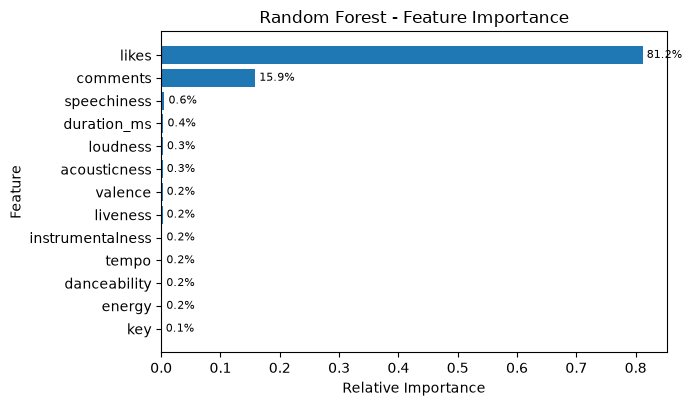

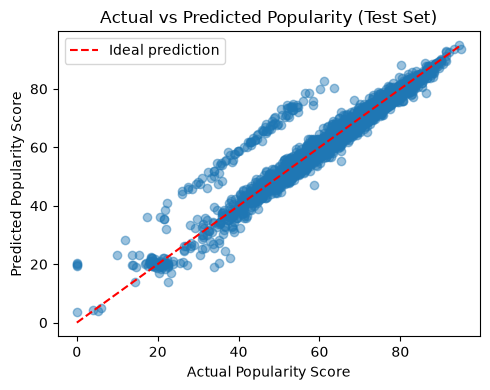

Feature importance saved to: d:\BDA\spotify_model_outputs\feature_importance.csv


In [15]:

# 1. Feature importance and relative weights
importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

total_importance = importance_df["Importance"].sum()

importance_df["Weight (%)"] = (
    (importance_df["Importance"] / total_importance) * 100
).round(2) if total_importance > 0 else 0.0

print("Feature Importance and Relative Weights:")
display(importance_df)

# Save importance table
importance_path = os.path.join(OUTPUT_DIR, "feature_importance.csv")
importance_df.to_csv(importance_path, index=False)

# 2. Feature importance graph
plot_df = importance_df.sort_values("Importance", ascending=True)

fig, ax = plt.subplots(
    figsize=(7, max(3, 0.32 * len(plot_df)))
)

bars = ax.barh(plot_df["Feature"], plot_df["Importance"])

ax.set_title("Random Forest - Feature Importance")
ax.set_xlabel("Relative Importance")
ax.set_ylabel("Feature")

for bar, weight in zip(bars, plot_df["Weight (%)"]):
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f" {weight:.1f}%",
        va="center",
        fontsize=8
    )

plt.tight_layout()
plt.show()
plt.close()

# 3. Actual vs Predicted Popularity
fig, ax = plt.subplots(figsize=(5, 4))

ax.scatter(y_test, test_pred, alpha=0.45)

low = min(float(y_test.min()), float(np.min(test_pred)))
high = max(float(y_test.max()), float(np.max(test_pred)))

ax.plot([low, high], [low, high], "r--", label="Ideal prediction")
ax.set_title("Actual vs Predicted Popularity (Test Set)")
ax.set_xlabel("Actual Popularity Score")
ax.set_ylabel("Predicted Popularity Score")
ax.legend()

plt.tight_layout()
plt.show()
plt.close()

print("Feature importance saved to:", os.path.abspath(importance_path))


## 8. Audio-based song recommendations (Top 5 / Top 10)

In [16]:
# Recommendations use only audio features as well.
rec_df = df.copy()
rec_X = rec_df[audio_features].apply(pd.to_numeric, errors="coerce")
rec_X = rec_X.replace([np.inf, -np.inf], np.nan)
rec_medians = rec_X.median().fillna(0)
rec_X = rec_X.fillna(rec_medians)

scaler = StandardScaler()
R_scaled = scaler.fit_transform(rec_X)
nn = NearestNeighbors(metric="cosine", algorithm="brute").fit(R_scaled)

def recommend_songs(song_query, top_n=5):
    matches = rec_df.index[
        rec_df[track_col].astype(str).str.contains(str(song_query), case=False, na=False, regex=False)
    ].tolist()
    if not matches:
        print("No song match. Try a shorter title.")
        return pd.DataFrame()
    source_idx = matches[0]
    pos = rec_df.index.get_loc(source_idx)
    _, indices = nn.kneighbors(R_scaled[[pos]], n_neighbors=min(top_n + 1, len(rec_df)))
    rec_positions = [i for i in indices[0] if i != pos][:top_n]
    display_cols = [c for c in [track_col, artist_col, "popularity_score"] if c and c in rec_df.columns]
    result = rec_df.iloc[rec_positions][display_cols].copy()
    result.insert(0, "rank", range(1, len(result) + 1))
    return result

example_track = str(rec_df.iloc[0][track_col])
print("Example song:", example_track)
display(recommend_songs(example_track, 5))
# Example: recommend_songs("song title", 10)


Example song: The Passenger


,rank,track,artist,popularity_score
10046,1,Do You Want To,Franz Ferdinand,66.594487
3509,2,Psycho,Muse,75.582656
13228,3,Vida de Cão,Rionegro & Solimões,61.089776
16702,4,"I Like It, I Love It",Tim McGraw,62.026730
20156,5,Gasoline,I Prevail,67.755119


## 9. Save results without overwriting existing data

In [17]:
# Create the output table if needed.
session.execute("""
CREATE TABLE IF NOT EXISTS song_popularity_results (
    song_id text PRIMARY KEY,
    track text,
    artist text,
    popularity_score double
)
""")

existing_rows = session.execute("SELECT song_id FROM song_popularity_results")
existing_ids = {str(r.song_id) for r in existing_rows}
print("Existing result rows:", len(existing_ids))

insert_stmt = session.prepare("""
INSERT INTO song_popularity_results (song_id, track, artist, popularity_score)
VALUES (?, ?, ?, ?)
""")

def safe_text(value):
    return "" if pd.isna(value) else str(value)

inserted = skipped = 0
for _, row in df.iterrows():
    track_value = safe_text(row[track_col]) if track_col else ""
    artist_value = safe_text(row[artist_col]) if artist_col else ""
    if id_col and pd.notna(row.get(id_col)):
        song_id = safe_text(row[id_col])
    else:
        song_id = str(uuid5(NAMESPACE_URL, track_value + "|" + artist_value))

    if song_id in existing_ids:
        skipped += 1
        continue

    score = float(row["popularity_score"]) if pd.notna(row["popularity_score"]) else 0.0
    session.execute(insert_stmt, (song_id, track_value, artist_value, score))
    existing_ids.add(song_id)
    inserted += 1

print(f"Inserted new rows: {inserted}; skipped existing rows: {skipped}")

csv_path = os.path.join(OUTPUT_DIR, "processed_songs.csv")
if os.path.exists(csv_path):
    print("CSV already exists; not overwriting:", os.path.abspath(csv_path))
else:
    df.drop(columns=[c for c in ["_track_key", "_match_key"] if c in df.columns]).to_csv(csv_path, index=False)
    print("Saved processed CSV:", os.path.abspath(csv_path))


Existing result rows: 20626
Inserted new rows: 0; skipped existing rows: 20626
CSV already exists; not overwriting: d:\BDA\spotify_model_outputs\processed_songs.csv


## 10. Cleanup (optional)

When finished, you can close Cassandra connections:
```python
# cluster.shutdown()
```

### Troubleshooting
- If the CSV is not found, update `AUDIO_CSV_PATH` in Section 1.
- If zero songs match, inspect the printed sample track/artist names and ensure the correct CSV is used.
- This notebook intentionally stops rather than inventing missing audio features.
- A high/low score is a custom engagement-derived target, not Spotify's official popularity score.
